# Giving a VLA 3-D perception: pointmaps, frames, occlusion 🧊
### The perception-VLA interface, step by step

**Code:** `src/Halo_VLA/vla_foundations/world3d.py` (pinhole cameras, ray-cast renderer, depth and **pointmaps**), `policy3d.py` (`Policy3D`, input representations, `pointmaps_to_bev`) ·
**papers:** PointVLA ([arXiv:2503.07511](https://arxiv.org/abs/2503.07511)), SpatialVLA ([2501.15830](https://arxiv.org/abs/2501.15830)), *See like a Robot: Robot-Centric Pointmaps for VLA Models* / SeeR-VLA ([2607.11498](https://arxiv.org/abs/2607.11498)).

Most VLAs read **2-D RGB frames**; the robot acts in **3-D**. Contact-rich manipulation needs depth, occlusion handling and a notion of *where things are in the robot's frame*, which is exactly where a perception background is an advantage. This notebook builds a small 3-D world and asks, with measurements:

| part | question | experiment |
|---|---|---|
| 1 | what is a **pointmap**, and in which **frame** should it live? | pinhole math by hand, depth → pointmap in camera and robot frames |
| 2 | why is a single RGB image **ambiguous**? | two scenes, one image |
| 3 | which input representation lets a policy act well, for a fixed *and* for a changing camera? | RGB / RGB-D / camera-frame pointmap / robot-frame pointmap / bird's-eye raster |
| 4 | what about **occlusion**? | a pillar hides the target from one camera; a second view + a view-independent representation |
| 5 | where does **classical perception** still win? | precision of a segmentation-and-geometry pipeline vs the learned policy |

### Where this notebook corrects the usual summary
* **Verified, with what the papers say**: *PointVLA* keeps the pre-trained action expert **frozen**, adds point-cloud features through a small modular block, and uses a **skip-block analysis** to inject them only into the least useful expert blocks. *SpatialVLA* adds an **Ego3D position encoding** computed in the *camera* frame (so no robot-to-camera calibration is needed). *SeeR-VLA* argues the opposite
  trade: actions are defined in the **robot** frame, so lift RGB-D to pointmaps, transform them with the extrinsics into the robot frame (re-origined at the end effector) and **add the pointmap features to the RGB features** (the token count does not change); the authors report gains on RoboCasa for π0.5 and SmolVLA, and a larger advantage when the camera placement was not seen in training.
  I could not verify specific numbers quoted elsewhere (e.g. a "+23.7 pp over PointVLA"), so none are used here: the notebook *measures* the camera-frame vs robot-frame question itself (Step 5).
* "2 RGB frames of context" is a property of particular models (π0 uses several camera views, a short history in others), not of VLAs in general.

| | published | this notebook |
|---|---|---|
| geometry encoder | pretrained point-cloud / pointmap encoders | a patch transformer on 6 input channels |
| cameras | 1-3 views, real calibration noise | 1-2 simulated pinhole views, exact calibration |
| task | contact-rich manipulation | reach the named cube in 3-D (position only) |

## Step 0: A 3-D tabletop

Three coloured cubes float at random heights above a table (`z ∈ {0.05, 0.15, 0.25}`); the robot's end effector starts anywhere and must reach the cube named by the instruction (a colour). The **robot frame** has `x, y` along the table and `z` up. The policy gets the **end-effector position** (proprioception), the **instruction**, and a camera image
of one of several possible kinds. The expert moves in a straight line at one `max_step = 0.05` per tick.

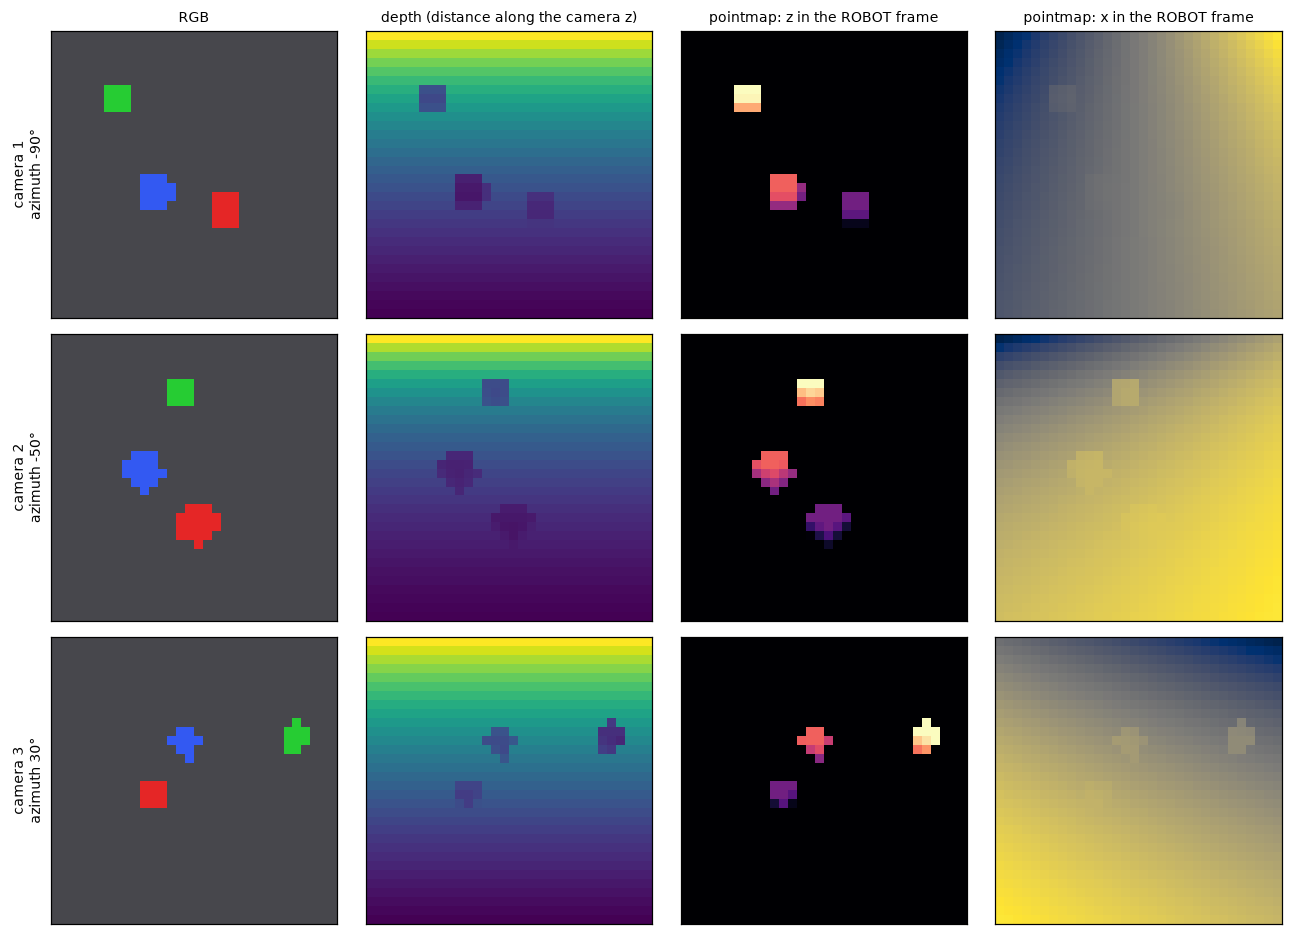

cube centres in the robot frame: {'red': [0.64, 0.35, 0.05], 'green': [0.15, 0.83, 0.25], 'blue': [0.36, 0.37, 0.15]}


In [1]:
import time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots

from vla_foundations.world3d import COLORS3D, Camera, expert_action, random_camera, render, sample_scene
from vla_foundations.policy3d import CHANNELS, Dataset3D, Policy3D, channels, pointmaps_to_bev, rollout3d, train3d

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
rng = np.random.default_rng(3)
scene = sample_scene(rng)
cams = [Camera.from_angles(-90, 50, 1.2), Camera.from_angles(-50, 40, 1.1), Camera.from_angles(30, 55, 1.3)]
fig, axes = plt.subplots(3, 4, figsize=(12, 8.6))
for r, cam in enumerate(cams):
    ob = render(scene, cam)
    axes[r, 0].imshow(ob.rgb.transpose(1, 2, 0)); axes[r, 1].imshow(ob.depth, cmap="viridis"); axes[r, 2].imshow(ob.points_robot[2], cmap="magma"); axes[r, 3].imshow(ob.points_cam[2] if False else ob.points_robot[0], cmap="cividis")
    for c, t in zip(range(4), ("RGB", "depth (distance along the camera z)", "pointmap: z in the ROBOT frame", "pointmap: x in the ROBOT frame")):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(t, fontsize=9)
    axes[r, 0].set_ylabel(f"camera {r + 1}\nazimuth {[-90, -50, 30][r]}°", fontsize=9)
plt.tight_layout(); plt.show()
print("cube centres in the robot frame:", {c: p.round(2).tolist() for c, p in scene.objects.items()})

# Part 1: Pinhole cameras, depth and pointmaps

## Step 1: The geometry, by hand

A camera with focal length `f` (pixels) and principal point `(c_x, c_y)` projects a point `P = (X, Y, Z)` **in the camera frame** (x right, y down, z forward) to the pixel
$$u = f\,\frac{X}{Z} + c_x,\qquad v = f\,\frac{Y}{Z} + c_y,\qquad Z = \text{depth}.$$
Inverting it with a measured depth gives the 3-D point **(unprojection)**: `X = (u − c_x) Z / f`, `Y = (v − c_y) Z / f`. The camera's pose in the robot frame is the **extrinsic** transform `P_robot = R ᵀ P_cam + t` (here `t` is the camera position and the rows of `R` are the camera axes).
A **pointmap** stores, for every pixel, the 3-D point it sees: in the camera frame (`points_cam`) or, after the extrinsic transform, in the **robot frame** (`points_robot`). Camera-frame pointmaps are cheap but *change with the camera pose*; robot-frame pointmaps are *the same wherever the camera is*, but need calibration. We verify the maths.

In [2]:
cam = cams[1]
pts = np.stack(list(scene.objects.values()))
uvd = cam.project(pts)
back = cam.unproject(uvd[:, 0], uvd[:, 1], uvd[:, 2])
print("focal length f = (S/2)/tan(fov/2) =", round(cam.focal, 2), "pixels (S = 32, fov = 55°)")
print("project → unproject round trip, max error:", float(np.abs(back - pts).max()))
ob = render(scene, cam)
print("pointmap in the robot frame at a cube's pixel vs the cube's true surface:")
for name, p, (u, v, d) in zip(scene.objects, pts, uvd):
    u_i, v_i = int(u), int(v)
    seen = ob.points_robot[:, v_i, u_i]
    print(f"   {name:5s} centre {p.round(3)}  pixel ({u_i:2d},{v_i:2d}) depth {d:.3f}  → pointmap sees {seen.round(3)}  (a point on the cube's surface, {np.linalg.norm(seen - p):.3f} from the centre)")
# the same table corner seen by two cameras: identical in the robot frame, different in the camera frame
corner = np.array([[0.1, 0.1, 0.0]])
for c in (cams[0], cams[2]):
    print("table corner in camera frame:", c.to_camera(corner).round(3), "| in robot frame:", corner[0])

focal length f = (S/2)/tan(fov/2) = 30.74 pixels (S = 32, fov = 55°)
project → unproject round trip, max error: 2.498001805406602e-16
pointmap in the robot frame at a cube's pixel vs the cube's true surface:
   red   centre [0.637 0.355 0.05 ]  pixel (16,21) depth 0.979  → pointmap sees [0.674 0.316 0.1  ]  (a point on the cube's surface, 0.073 from the centre)
   green centre [0.151 0.831 0.25 ]  pixel (14, 6) depth 1.370  → pointmap sees [0.18  0.781 0.275]  (a point on the cube's surface, 0.063 from the centre)
   blue  centre [0.359 0.37  0.15 ]  pixel (10,15) depth 1.061  → pointmap sees [0.409 0.332 0.18 ]  (a point on the cube's surface, 0.070 from the centre)
table corner in camera frame: [[-0.4    0.371  1.019]] | in robot frame: [0.1 0.1 0. ]
table corner in camera frame: [[-0.146 -0.39   1.695]] | in robot frame: [0.1 0.1 0. ]


## Step 2: One image, two scenes

A single RGB view collapses a **ray** to a pixel: every point on the ray through a pixel looks the same *except for its apparent size*. We place the red cube at two places on the same ray from the camera, the second `0.25` closer to the camera (so higher above the table), and compare the two images.

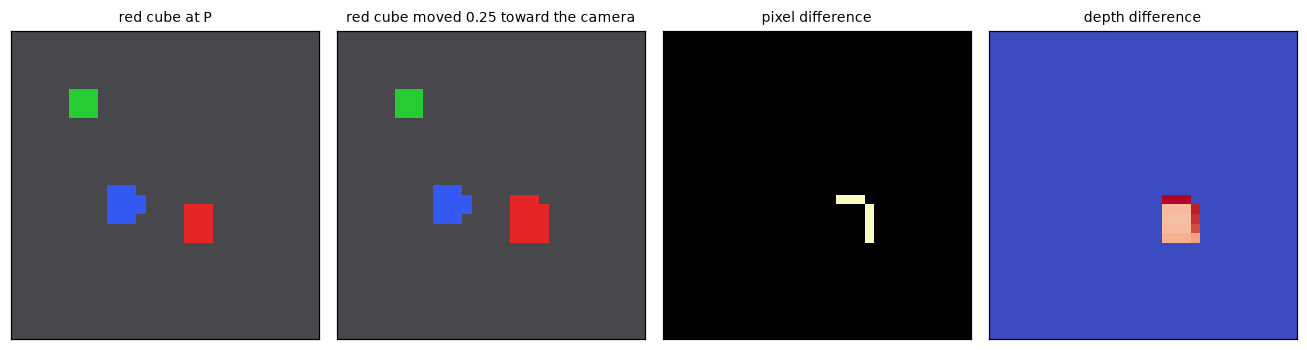

red pixels: 12 vs 19 | the two cube centres are 0.25 apart in 3-D (5 action steps) but differ in the image only by the cube's apparent size


In [3]:
cam = cams[0]
base = scene.objects["red"]
ray = base - cam.position; ray = ray / np.linalg.norm(ray)
far = base - 0.25 * ray                     # 0.25 closer to the camera, on the same ray
import copy
scene_b = copy.deepcopy(scene); scene_b.objects["red"] = far
imgs = [render(sc, cam) for sc in (scene, scene_b)]
diff = np.abs(imgs[0].rgb - imgs[1].rgb).sum(0)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.1))
axes[0].imshow(imgs[0].rgb.transpose(1, 2, 0)); axes[0].set_title("red cube at P", fontsize=9)
axes[1].imshow(imgs[1].rgb.transpose(1, 2, 0)); axes[1].set_title("red cube moved 0.25 toward the camera", fontsize=9)
axes[2].imshow(diff, cmap="magma"); axes[2].set_title("pixel difference", fontsize=9)
axes[3].imshow(imgs[0].depth - imgs[1].depth, cmap="coolwarm"); axes[3].set_title("depth difference", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print(f"red pixels: {int(((np.abs(imgs[0].rgb - np.array(COLORS3D['red'])[:, None, None]).sum(0)) < 1e-3).sum())} vs {int(((np.abs(imgs[1].rgb - np.array(COLORS3D['red'])[:, None, None]).sum(0)) < 1e-3).sum())} | "
      f"the two cube centres are {np.linalg.norm(far - base):.2f} apart in 3-D (5 action steps) but differ in the image only by the cube's apparent size")

The two scenes are **0.25 apart in 3-D** (five action steps!) yet the two images differ only in the cube's apparent size (12 against 19 red pixels) and its few border pixels: the *position along the ray* is carried only by a subtle size cue, while the **depth** map differs by exactly that amount. This is the structural reason RGB-only VLAs are imprecise in depth and why 3-D inputs help *contact-rich* tasks.

# Part 2: Which representation?

## Step 3: Five inputs, one policy

`Policy3D` is a small transformer: the image is cut into 4×4 patches, **one query token** (the instruction's colour + the end-effector position) is appended, and the output is the next 3-D action. Only the **input channels** change:

| name | channels | frame | needs calibration? |
|---|---|---|---|
| `rgb` | RGB (3) | – | no |
| `rgbd` | RGB + depth (4) | camera | intrinsics |
| `rgb+pcam` | RGB + camera-frame pointmap (6) | camera | intrinsics |
| `rgb+probot` | RGB + **robot-frame** pointmap (6) | robot | intrinsics + extrinsics |
| `bev` | colour + height of the highest point per cell (4) | robot, top-down | intrinsics + extrinsics |

(`bev` rasterises the robot-frame pointmap of one or more cameras into a top-down grid, the representation the Halos-lift / BEVFormer notebooks of this repository build with learned lifting; here it is a simple, non-learned lift.) Two settings: a **fixed** camera (every episode uses the same viewpoint) and a **random** camera (azimuth ±60°, elevation 35-65°, distance 1.0-1.4).

In [4]:
STEPS, SCENES = 2500, 3000
modes = ["rgb", "rgbd", "rgb+pcam", "rgb+probot", "bev"]
results = {}
for fixed in (True, False):
    for mode in modes:
        t0 = time.time()
        train = Dataset3D(SCENES, mode, fixed, seed=0); test = Dataset3D(200, mode, fixed, seed=99)
        torch.manual_seed(0)
        model = Policy3D(CHANNELS[mode])
        losses = train3d(model, train, steps=STEPS, seed=0); model.eval()
        r = rollout3d(model, test, 200, seed=1)
        results[(fixed, mode)] = r
        print(f"camera {'fixed ' if fixed else 'random'} {mode:11s} loss {np.mean(losses[-100:]):.4f} | success {r['success']:.2f} | final error {r['final_error']:.3f} | {time.time() - t0:.0f} s", flush=True)

camera fixed  rgb         loss 0.0152 | success 0.62 | final error 0.070 | 212 s


camera fixed  rgbd        loss 0.0045 | success 0.92 | final error 0.048 | 221 s


camera fixed  rgb+pcam    loss 0.0079 | success 0.83 | final error 0.054 | 204 s


camera fixed  rgb+probot  loss 0.0041 | success 0.93 | final error 0.046 | 199 s


camera fixed  bev         loss 0.0013 | success 1.00 | final error 0.039 | 214 s


camera random rgb         loss 0.0657 | success 0.09 | final error 0.171 | 247 s


camera random rgbd        loss 0.0542 | success 0.21 | final error 0.149 | 232 s


camera random rgb+pcam    loss 0.0576 | success 0.18 | final error 0.155 | 247 s


camera random rgb+probot  loss 0.0052 | success 0.89 | final error 0.049 | 224 s


camera random bev         loss 0.0017 | success 0.99 | final error 0.040 | 214 s


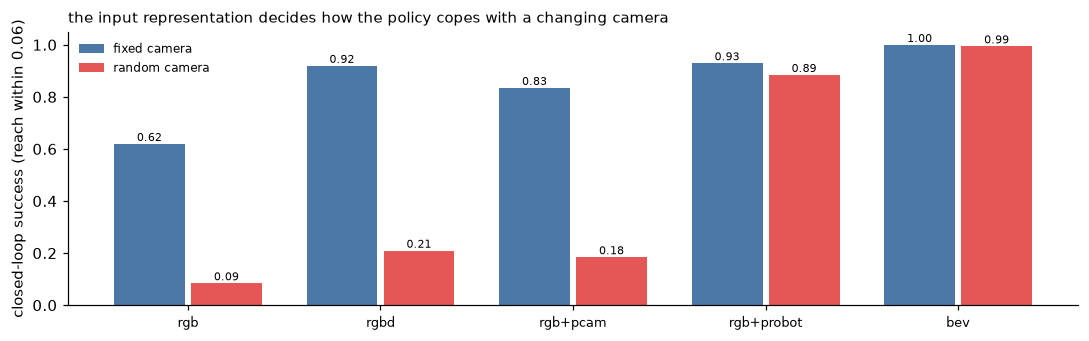

In [5]:
plots.grouped_bars({m: {"fixed camera": results[(True, m)]["success"], "random camera": results[(False, m)]["success"]} for m in modes}, "closed-loop success (reach within 0.06)", "the input representation decides how the policy copes with a changing camera", colors=["#4c78a8", "#e45756"])

**Reading the bars** (one seed, 200 test scenes; the gaps are large).

* **Fixed camera: geometry helps even when nothing else changes.** RGB alone reaches 0.62 (the cube's *apparent size* gives a rough depth), RGB + depth 0.92, a camera-frame pointmap 0.83, a robot-frame pointmap 0.93 and the bird's-eye raster 1.00. The 38 % of RGB failures are the depth ambiguity of Step 2.
* **Random camera: the *frame* matters more than the presence of depth.** RGB collapses to **0.08**, and so do RGB-D (**0.21**) and the camera-frame pointmap (**0.19**): a camera-frame pointmap changes its meaning with every camera pose, and the policy, whose actions live in the robot frame, would have to infer the pose from the image. The **robot-frame pointmap keeps 0.89** and the **bird's-eye raster 0.995**.
  This is the SeeR-VLA thesis made measurable (our numbers: one seed, a toy; theirs: RoboCasa and real robots).
* Why does the raster beat the robot-frame pointmap channels? The latter are laid out in *image* space, so the table's layout must still be re-learned for every camera; the raster is aligned with the table and with the action space.

## Step 4: Occlusion

A tall pillar stands between the *fixed* camera and the target: the target cube is **hidden** in that view. We evaluate (on occluded scenes only) a policy using the single occluding view, in RGB and in the bird's-eye representation, and the bird's-eye representation built from **two** views (the second sees the target from the opposite side). The point of a **view-independent, robot-frame** representation is that views can be *merged* without any learning.

RGB, occluding view    success 0.41 | final error 0.103


BEV, occluding view    success 0.71 | final error 0.077


BEV, two views         success 0.94 | final error 0.044


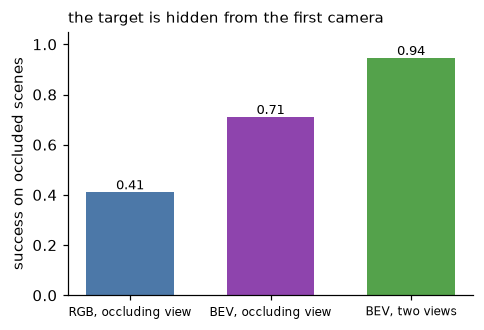

In [6]:
occ = {}
for name, mode, second in (("RGB, occluding view", "rgb", False), ("BEV, occluding view", "bev", False), ("BEV, two views", "bev", True)):
    train = Dataset3D(SCENES, mode, True, seed=0, occluder=True, second_camera=second); test = Dataset3D(200, mode, True, seed=99, occluder=True, second_camera=second)
    torch.manual_seed(0)
    model = Policy3D(CHANNELS[mode]); train3d(model, train, steps=STEPS, seed=0); model.eval()
    occ[name] = rollout3d(model, test, 200, seed=1)
    print(f"{name:22s} success {occ[name]['success']:.2f} | final error {occ[name]['final_error']:.3f}", flush=True)
plots.bar_compare({k: v["success"] for k, v in occ.items()}, "success on occluded scenes", "the target is hidden from the first camera", ylim=(0, 1.05), colors=["#4c78a8", "#8e44ad", "#54a24b"])

**What the measurements say** (scenes with a pillar between the fixed camera and the target, plus a decoy pillar; one seed).

* **RGB from the occluding view: 0.41.** The target is mostly hidden; the policy guesses from where the hidden object *could* be.
* **The bird's-eye raster from the *same* single view: 0.71.** Better, but still blind to the hidden cube. (Part of this is *leakage*: the pillar stands in front of the target, so its position is a weak cue to where the target is; the random offset and the decoy pillar reduce that but cannot remove it. Real occlusions leak too: objects hide behind things that are usually near them.)
* **The bird's-eye raster from two views: 0.94.** The second camera sees the target from the other side; because both views are expressed in the **robot frame**, their pointmaps merge by simply writing both into the same grid, with no learning and no alignment network. Fusing views by stacking *camera-frame* channels would not even be well defined.

## Step 5: Where does classical perception still win?

A VLA is a good generalist and a poor *metrologist*. A classical pipeline for the same job, **segment the named colour, average the 3-D points of its pixels, correct for the visible-surface bias**, localises the object with centimetre accuracy from one pointmap and needs no training at all. We compare its error with the policy's final positioning error (Step 3, `rgb+probot`, random camera).

In [7]:
def classical_estimate(ob, colour, half=0.05):
    mask = np.abs(ob.rgb - np.array(COLORS3D[colour])[:, None, None]).sum(0) < 1e-3
    if not mask.any():
        return None
    p = ob.points_robot[:, mask].mean(1)                 # centroid of the visible surface points, robot frame
    toward_camera = ob.camera.position - p
    return p - half * toward_camera / np.linalg.norm(toward_camera)   # push from the visible surface to the cube centre (known size)
errs = []
rng_c = np.random.default_rng(5)
for _ in range(400):
    sc = sample_scene(rng_c); cam = random_camera(rng_c); ob = render(sc, cam)
    colour = list(COLORS3D)[int(rng_c.integers(3))]
    est = classical_estimate(ob, colour)
    if est is not None:
        errs.append(np.linalg.norm(est - sc.objects[colour]))
errs = np.array(errs)
print(f"classical pipeline (segmentation + pointmap centroid, no learning): localisation error median {np.median(errs):.3f}, 90th percentile {np.percentile(errs, 90):.3f}, from {len(errs)} of 400 views (the cube was visible)")
print(f"learned policy: mean final positioning error {results[(False, 'rgb+probot')]['final_error']:.3f} (random camera) | success radius used: 0.06")

classical pipeline (segmentation + pointmap centroid, no learning): localisation error median 0.017, 90th percentile 0.022, from 400 of 400 views (the cube was visible)
learned policy: mean final positioning error 0.049 (random camera) | success radius used: 0.06


**The classical pipeline localises the cube to about 1.7 cm (median; 2.2 cm at the 90th percentile)** with no training, from a single 32×32 pointmap, against **≈ 4.9 cm mean final error** for the learned policy (it only needs to get within 6 cm to succeed, and nothing asks it to do better). For a task where a few millimetres matter (insertion, threading) that gap decides the design: use perception that is *accurate by construction* to place the end effector, and let the VLA decide *what* and *whether*.
(The estimate fails when the cube is not visible, which is exactly where the learned, multi-view representation helps: the two are complements, not rivals.)

## Step 6: Design options, and where I would put a VLA in a perception-planning stack

| option | idea | frame | trade-off |
|---|---|---|---|
| RGB only | rely on the VLM's 2-D features | – | simplest; imprecise depth; no explicit geometry |
| add depth / pointmap to the image tokens | extra channels, same token count | camera (SpatialVLA's Ego3D) | no calibration needed; features change with the camera pose |
| **robot-frame pointmap** (SeeR-VLA) | transform with the extrinsics, add to RGB features | robot / end effector | actions and observations share a frame: transfers across camera placements; needs calibration |
| inject a point-cloud encoder into the action expert (PointVLA) | frozen expert + small modular 3-D block | robot or camera | keeps the pre-trained model; adds an encoder |
| bird's-eye / voxel grid | top-down raster of the fused cloud | robot | merges views for free (Step 4); loses vertical detail |

**Where would I place a VLA in an existing autonomous perception-planning stack, and what would I keep classical?** The VLA owns **intent and semantics**: *which* object, *what* to do with it, the generalisation to new instructions and objects, and a first, coarse trajectory. Classical components keep what must be *accurate, calibrated or certified*: the **sensor calibration and time synchronisation**, **6-DoF pose of known objects** (feature- or model-based
registration when a CAD model exists; Step 5), **free-space and collision geometry** (occupancy / signed distance fields from the depth stream, so that the VLA's waypoints are *checked* before execution), the **motion planner / MPC** that turns waypoints into feasible, smooth, limit-respecting trajectories, and the **low-level impedance controller** (see the control notebook).
The VLA's output is a *proposal*; a classical safety layer is the *guarantee*. Where classical perception still wins: precise pose on texture-less or reflective surfaces *with a model-based pipeline that handles them explicitly*, metric accuracy, repeatability; where it loses: open-vocabulary recognition, clutter, and anything not on the engineered list.

**Take-aways.** (1) A pointmap is a per-pixel 3-D point; the **frame** it is expressed in decides whether a policy trained with one camera works with another. (2) A single RGB view cannot place an object along its ray; depth fixes that. (3) Fusing views is trivial in a **robot-frame** representation and impossible by stacking camera-frame channels. (4) Classical perception localises a known object more precisely than a learned policy and should be kept for that job; the VLA adds what classical systems lack.

### 🧪 Exercises
1. Give the camera **calibration noise** (a few degrees of extrinsic error) in `random_camera` for the robot-frame inputs only: how fast does `rgb+probot` degrade, and does `rgb+pcam` (which needs no extrinsics) win again?
2. Add **depth noise** (5 % multiplicative) and holes (zero depth for 10 % of pixels) to the pointmaps: which representation is the most robust?
3. Replace the non-learned `pointmaps_to_bev` by a **learned lift** (a small network that scatters features by predicted depth, as in the Lift-Splat / BEVFormer notebooks of this repository): does it beat the raster?
4. Feed `Policy3D` **both** `rgb` tokens and a separate `probot` token stream (SeeR-VLA's "add the features, same token count"): is the sum better than the concatenated channels?